In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)
df["text"] = df["headline"] + " " + df["body_text"]

print(df[["news_id", "label", "text"]].head())

   news_id label                                               text
0        1  Real  Global economy faces recession The Prime Minis...
1        2  Real  Earthquake hits Chittagong, panic spreads Gove...
2        3  Fake  Breakthrough in Bangladesh's tech industry Loc...
3        4  Fake  Dengue situation worsens in the country The Pr...
4        5  Real  New virus outbreak sparks fear Government sour...


In [2]:
def get_words(text):
    return re.findall(r"\b[a-zA-Z]+\b", str(text).lower())

def get_sentences(text):
    sentences = re.split(r"[.!?]+", str(text))
    return [s.strip() for s in sentences if s.strip()]

df["word_count"] = df["text"].apply(lambda x: len(get_words(x)))

df["sentence_count"] = df["text"].apply(
    lambda x: max(1, len(get_sentences(x)))
)

df["average_sentence_length"] = (
    df["word_count"] / df["sentence_count"]
)

df["unique_word_count"] = df["text"].apply(
    lambda x: len(set(get_words(x)))
)

df["lexical_diversity"] = (
    df["unique_word_count"] / df["word_count"].clip(lower=1)
)

df["question_marks"] = df["text"].str.count(r"\?")
df["exclamation_marks"] = df["text"].str.count("!")

print(df[[
    "label", "word_count", "sentence_count",
    "average_sentence_length", "lexical_diversity",
    "question_marks", "exclamation_marks"
]].head())

  label  word_count  sentence_count  average_sentence_length  \
0  Real          15               1                     15.0   
1  Real          16               1                     16.0   
2  Fake          15               1                     15.0   
3  Fake          17               1                     17.0   
4  Real          16               1                     16.0   

   lexical_diversity  question_marks  exclamation_marks  
0           0.866667               0                  0  
1           1.000000               0                  0  
2           1.000000               0                  0  
3           0.823529               0                  0  
4           1.000000               0                  0  


In [3]:
linguistic_comparison = df.groupby("label").agg(
    average_word_count=("word_count", "mean"),
    average_sentence_count=("sentence_count", "mean"),
    average_sentence_length=("average_sentence_length", "mean"),
    average_lexical_diversity=("lexical_diversity", "mean"),
    average_question_marks=("question_marks", "mean"),
    average_exclamation_marks=("exclamation_marks", "mean")
).round(3)

print(linguistic_comparison)

       average_word_count  average_sentence_count  average_sentence_length  \
label                                                                        
Fake               15.650                   1.207                   13.697   
Real               15.485                   1.189                   13.705   

       average_lexical_diversity  average_question_marks  \
label                                                      
Fake                       0.963                     0.0   
Real                       0.964                     0.0   

       average_exclamation_marks  
label                             
Fake                         0.0  
Real                         0.0  


In [4]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

tfidf_matrix = vectorizer.fit_transform(df["text"])

similarity_matrix = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", similarity_matrix.shape)

TF-IDF matrix shape: (2212, 98)
Similarity matrix shape: (2212, 2212)


In [5]:
labels = df["label"].astype(str).str.strip().str.lower().to_numpy()

fake_indices = np.where(labels == "fake")[0]
real_indices = np.where(labels == "real")[0]

def get_average_similarity(indices1, indices2, same_group=False):
    values = []

    for i in indices1:
        for j in indices2:
            if same_group and i >= j:
                continue
            values.append(similarity_matrix[i, j])

    return np.mean(values) if values else 0

fake_similarity = get_average_similarity(
    fake_indices, fake_indices, same_group=True
)

real_similarity = get_average_similarity(
    real_indices, real_indices, same_group=True
)

cross_similarity = get_average_similarity(
    fake_indices, real_indices
)

print("Fake-to-Fake Similarity:", round(fake_similarity, 4))
print("Real-to-Real Similarity:", round(real_similarity, 4))
print("Fake-to-Real Similarity:", round(cross_similarity, 4))

Fake-to-Fake Similarity: 0.1066
Real-to-Real Similarity: 0.1064
Fake-to-Real Similarity: 0.1056


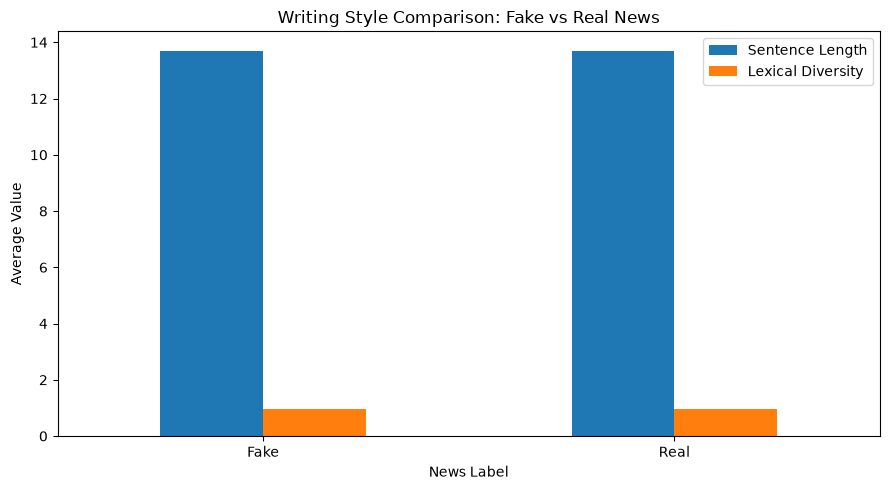

In [6]:
linguistic_comparison[[
    "average_sentence_length",
    "average_lexical_diversity"
]].plot(kind="bar", figsize=(9, 5))

plt.title("Writing Style Comparison: Fake vs Real News")
plt.xlabel("News Label")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(["Sentence Length", "Lexical Diversity"])
plt.tight_layout()
plt.show()

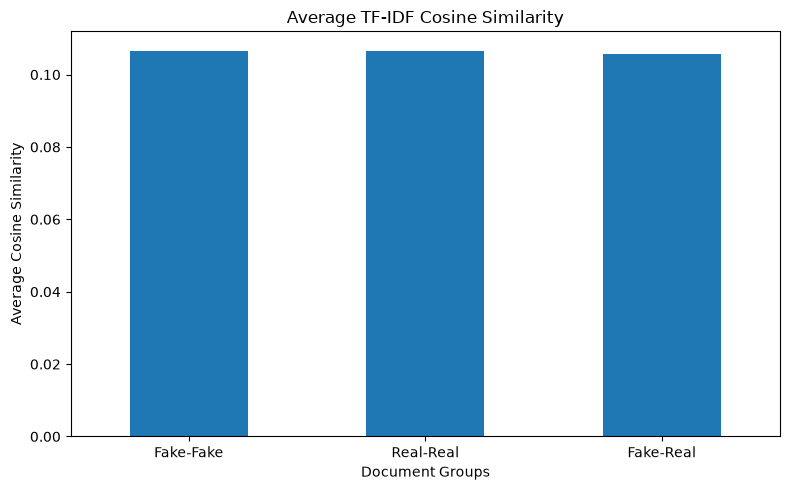

In [7]:
similarity_results = pd.Series({
    "Fake-Fake": fake_similarity,
    "Real-Real": real_similarity,
    "Fake-Real": cross_similarity
})

similarity_results.plot(kind="bar", figsize=(8, 5))

plt.title("Average TF-IDF Cosine Similarity")
plt.xlabel("Document Groups")
plt.ylabel("Average Cosine Similarity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
df.to_csv("T36_linguistic_profiling.csv", index=False)

linguistic_comparison.to_csv(
    "T36_linguistic_comparison.csv"
)

similarity_results.to_csv(
    "T36_similarity_comparison.csv",
    header=["average_similarity"]
)